# S&P 500 Capstone EDA — V2

# 1 Project Objective, Timing Rules, and Fixed Sample

Predict the S&P 500 return from the current Friday to the following Friday using economic, market, and valuation predictors. Daily predictor values follow the Thursday-information cutoff; weekly releases use information available by Friday night. The target is Friday-to-Friday return.

| Purpose | Observation dates | Weekly count |
|---|---|---:|
| Training | January 5, 2018–March 17, 2023 | 272 |
| Testing | March 24, 2023–September 25, 2026 | 184 |
| **Total model input observations** | | **456** |

Data source: updated V9, including the nine approved forward-P/E additions. All tables and graphs below use exactly these 456 complete observations. The October 2 forecast-only row is excluded. This revised EDA documents the completed study; combined-sample correlations and p-values are descriptive and are not used to select, tune, or alter the frozen model.


# 2 Import and Validation of the Fixed 456-Observation Sample

In [1]:
# Load the exact updated V9 series used by the model; no web downloads or V8 data.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
V9_PATH=Path(r"C:/Users/sethp/Documents/S Pomeroy - AI & Data Science/Springboard/9B) Capstone Project2/Springboard - Capstone Two Data Series V9 (update for missing forward PE values) (10 11 26).xlsx")
DATE_COL='model_week_end';TARGET_COL='target_return_next_w'
PREDICTOR_NAMES=['sp500_weekly_pct_chg','fed_funds_level','fed_funds_weekly_bp_chg','vix_level','vix_weekly_point_chg','treasury_10y_yield_level','tips_10y_yield_level','yield_spread_10y3m','baa10y_yield_spread','wti_weekly_pct_chg','broad_usd_weekly_pct_chg','initial_claims_weekly_pct_chg','wei_level','nfci_level','sp500_forward_pe_level']
SHEETS=['S01 SP500 Target','S02 SP500 Predictor','S03 Fed Funds Level','S04 Fed Funds Chg','S05 VIX Level','S06 VIX Chg','S07 10Y Yield','S08 10Y TIPS','S09 10Y3M Spread','S10 Baa10Y Spread','S11 WTI Chg','S12 USD Chg','S13 Claims Chg','S14 WEI Level','S15 NFCI Level','S16 Forward PE']
series=[]
with pd.ExcelFile(V9_PATH) as book:
 for sheet,label in zip(SHEETS,[TARGET_COL,*PREDICTOR_NAMES]):
  source=pd.read_excel(book,sheet_name=sheet,header=9)
  source[DATE_COL]=pd.to_datetime(source[DATE_COL]).dt.normalize()
  assert source[DATE_COL].is_unique
  series.append(pd.Series(pd.to_numeric(source.iloc[:,6],errors='raise').to_numpy(),index=source[DATE_COL],name=label))
 source_closes=pd.read_excel(book,sheet_name=SHEETS[0],header=9)
 source_closes[DATE_COL]=pd.to_datetime(source_closes[DATE_COL]).dt.normalize()
eda=pd.concat(series,axis=1).sort_index().loc['2018-01-05':'2026-09-25'].reset_index()
assert eda.shape==(456,17)
assert eda.notna().all().all()
assert eda[DATE_COL].equals(pd.Series(pd.date_range('2018-01-05','2026-09-25',freq='W-FRI'),name=DATE_COL))
display(eda.head())


,model_week_end,target_return_next_w,sp500_weekly_pct_chg,fed_funds_level,fed_funds_weekly_bp_chg,vix_level,vix_weekly_point_chg,treasury_10y_yield_level,tips_10y_yield_level,yield_spread_10y3m,baa10y_yield_spread,wti_weekly_pct_chg,broad_usd_weekly_pct_chg,initial_claims_weekly_pct_chg,wei_level,nfci_level,sp500_forward_pe_level
0,2018-01-05,0.015708,0.013563,1.42,0.0,9.22,-0.96,2.46,0.45,105.0,175.0,0.037940,-0.009194,-0.011952,2.86,-0.619,18.4
1,2018-01-12,0.008635,0.015995,1.42,0.0,9.88,0.66,2.54,0.54,111.0,169.0,0.021006,-0.006620,0.016129,2.62,-0.622,18.4
2,2018-01-19,0.022265,0.011010,1.42,0.0,12.22,2.34,2.62,0.57,117.0,164.0,0.040337,-0.004102,-0.087302,2.88,-0.622,18.4
3,2018-01-26,-0.038547,0.014732,1.42,0.0,11.58,-0.64,2.63,0.56,121.0,161.0,-0.008720,-0.008774,0.004348,3.07,-0.618,18.4
4,2018-02-02,-0.051620,-0.006083,1.42,0.0,13.47,1.89,2.78,0.67,130.0,156.0,0.032202,-0.011621,-0.012987,2.72,-0.609,18.0


In [2]:
# Validate the single agreed sample, with a separate training/test split.
training_eda=eda.loc[eda[DATE_COL].le('2023-03-17')].copy()
testing_eda=eda.loc[eda[DATE_COL].ge('2023-03-24')].copy()
assert len(training_eda)==272 and len(testing_eda)==184
assert len(eda)==456 and not eda[DATE_COL].duplicated().any()
STUDY_SAMPLE_SUMMARY=pd.DataFrame({'Purpose':['Training','Testing','Total model input observations'],'Observation dates':['January 5, 2018–March 17, 2023','March 24, 2023–September 25, 2026','January 5, 2018–September 25, 2026'],'Weekly count':[272,184,456]})
display(STUDY_SAMPLE_SUMMARY)
print('Forecast-only October 2 row is excluded; final observed next-week target ends October 2, 2026.')


,Purpose,Observation dates,Weekly count
0,Training,"January 5, 2018–March 17, 2023",272
1,Testing,"March 24, 2023–September 25, 2026",184
2,Total model input observations,"January 5, 2018–September 25, 2026",456


Forecast-only October 2 row is excluded; final observed next-week target ends October 2, 2026.


### 2.1 Data types, completeness, and descriptive statistics

The first table verifies the analytical data types and completeness of every field. The second summarizes the target and all 15 numeric predictors, providing their count, center, dispersion, range, and quartiles before any transformations or modeling decisions are considered.

In [3]:

data_quality = pd.DataFrame({
    "dtype": eda.dtypes.astype(str),
    "non_null": eda.notna().sum(),
    "missing": eda.isna().sum(),
    "unique_values": eda.nunique(dropna=False),
})

display(data_quality)

descriptive_stats = eda.describe().T

descriptive_stats.loc["model_week_end"] = (
    descriptive_stats.loc["model_week_end"].map(
        lambda value: (
            value.strftime("%Y-%m-%d")
            if isinstance(value, pd.Timestamp)
            else value
        )
    )
)

display(descriptive_stats)

,dtype,non_null,missing,unique_values
model_week_end,datetime64[ns],456,0,456
target_return_next_w,float64,456,0,456
sp500_weekly_pct_chg,float64,456,0,456
fed_funds_level,float64,456,0,61
fed_funds_weekly_bp_chg,float64,456,0,42
vix_level,float64,456,0,404
vix_weekly_point_chg,float64,456,0,399
treasury_10y_yield_level,float64,456,0,257
tips_10y_yield_level,float64,456,0,233
yield_spread_10y3m,float64,456,0,231


,count,mean,min,25%,50%,75%,max,std
model_week_end,456,2022-05-16,2018-01-05,2020-03-11,2022-05-16,2024-07-20,2026-09-25,NaN
target_return_next_w,456.0,0.002589,-0.149796,-0.010259,0.004758,0.015777,0.121017,0.025057
sp500_weekly_pct_chg,456.0,0.002603,-0.179666,-0.009666,0.00419,0.01516,0.104048,0.023906
fed_funds_level,456.0,2.659539,0.04,0.83,2.4,4.33,5.33,1.898133
fed_funds_weekly_bp_chg,456.0,0.539474,-90.0,0.0,0.0,0.0,75.0,10.649593
vix_level,456.0,19.630548,9.22,14.9675,17.695,22.4625,75.47,7.315069
vix_weekly_point_chg,456.0,0.012039,-14.33,-1.7025,-0.325,1.225,35.85,3.931315
treasury_10y_yield_level,456.0,2.983289,0.55,1.7675,3.035,4.2,5.18,1.284351
tips_10y_yield_level,456.0,0.835373,-1.15,-0.0625,0.925,1.89,2.85,1.12783
yield_spread_10y3m,456.0,23.638158,-189.0,-22.0,33.0,88.25,220.0,94.848396


# 3 S&P 500 Closing-Level Context

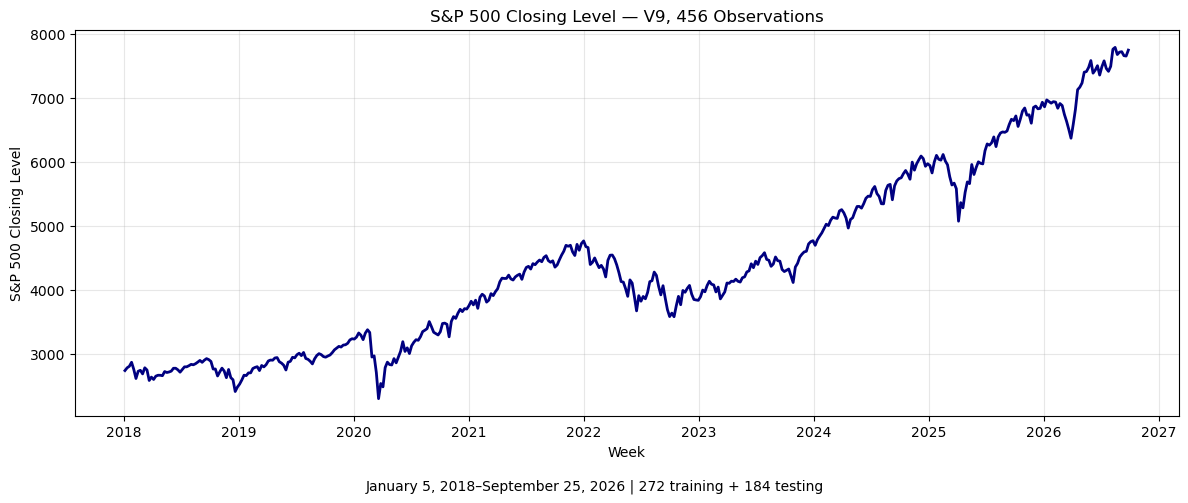

In [4]:
# Closing levels come directly from V9, aligned to the same 456 observation dates.
sp500_chart=eda[[DATE_COL]].merge(source_closes[[DATE_COL,'current_source_value']],on=DATE_COL,validate='one_to_one').rename(columns={'current_source_value':'sp500_close'})
assert len(sp500_chart)==456 and sp500_chart['sp500_close'].notna().all()
fig,ax=plt.subplots(figsize=(12,5));ax.plot(sp500_chart[DATE_COL],sp500_chart['sp500_close'],color='navy',linewidth=2)
ax.set(title='S&P 500 Closing Level — V9, 456 Observations',xlabel='Week',ylabel='S&P 500 Closing Level')
ax.grid(alpha=.3);fig.text(.5,.01,'January 5, 2018–September 25, 2026 | 272 training + 184 testing',ha='center');plt.tight_layout(rect=(0,.04,1,1));plt.show()


# 4 Target Distribution and Time-Series Behavior

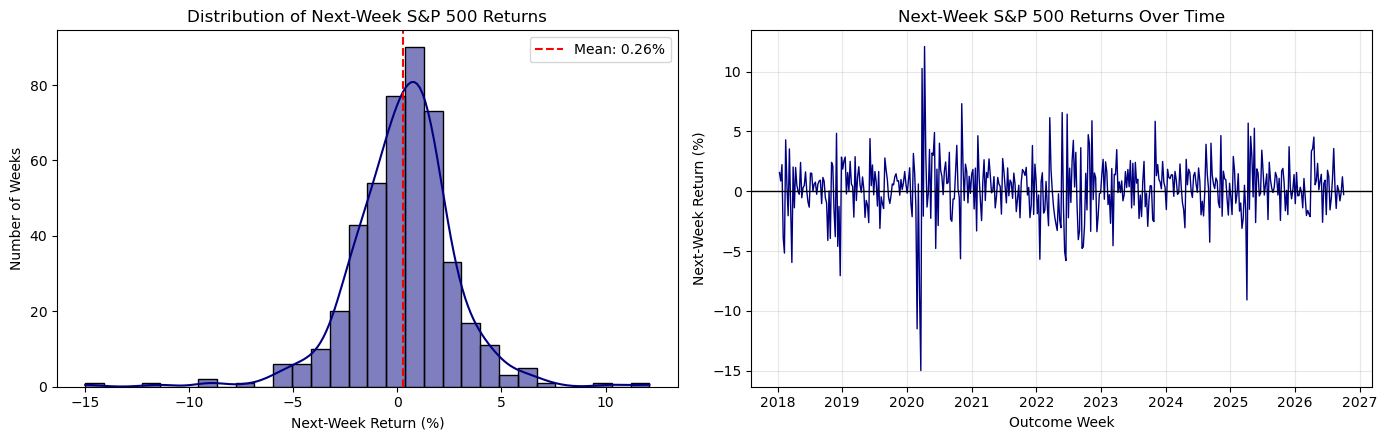

456-week target mean: 0.259%; median: 0.476%; standard deviation: 2.506%.


In [5]:

target_pct = eda["target_return_next_w"] * 100

target_outcome_date = (
    eda["model_week_end"] + pd.Timedelta(days=7)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4.5)
)

sns.histplot(
    target_pct,
    bins=30,
    kde=True,
    color="navy",
    ax=axes[0]
)

axes[0].axvline(
    target_pct.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {target_pct.mean():.2f}%"
)

axes[0].set_title("Distribution of Next-Week S&P 500 Returns")
axes[0].set_xlabel("Next-Week Return (%)")
axes[0].set_ylabel("Number of Weeks")
axes[0].legend()

axes[1].plot(
    target_outcome_date,
    target_pct,
    color="navy",
    linewidth=1
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title("Next-Week S&P 500 Returns Over Time")
axes[1].set_xlabel("Outcome Week")
axes[1].set_ylabel("Next-Week Return (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
print(f'456-week target mean: {target_pct.mean():.3f}%; median: {target_pct.median():.3f}%; standard deviation: {target_pct.std():.3f}%.')


# 5 Univariate Analysis of All 15 Predictors

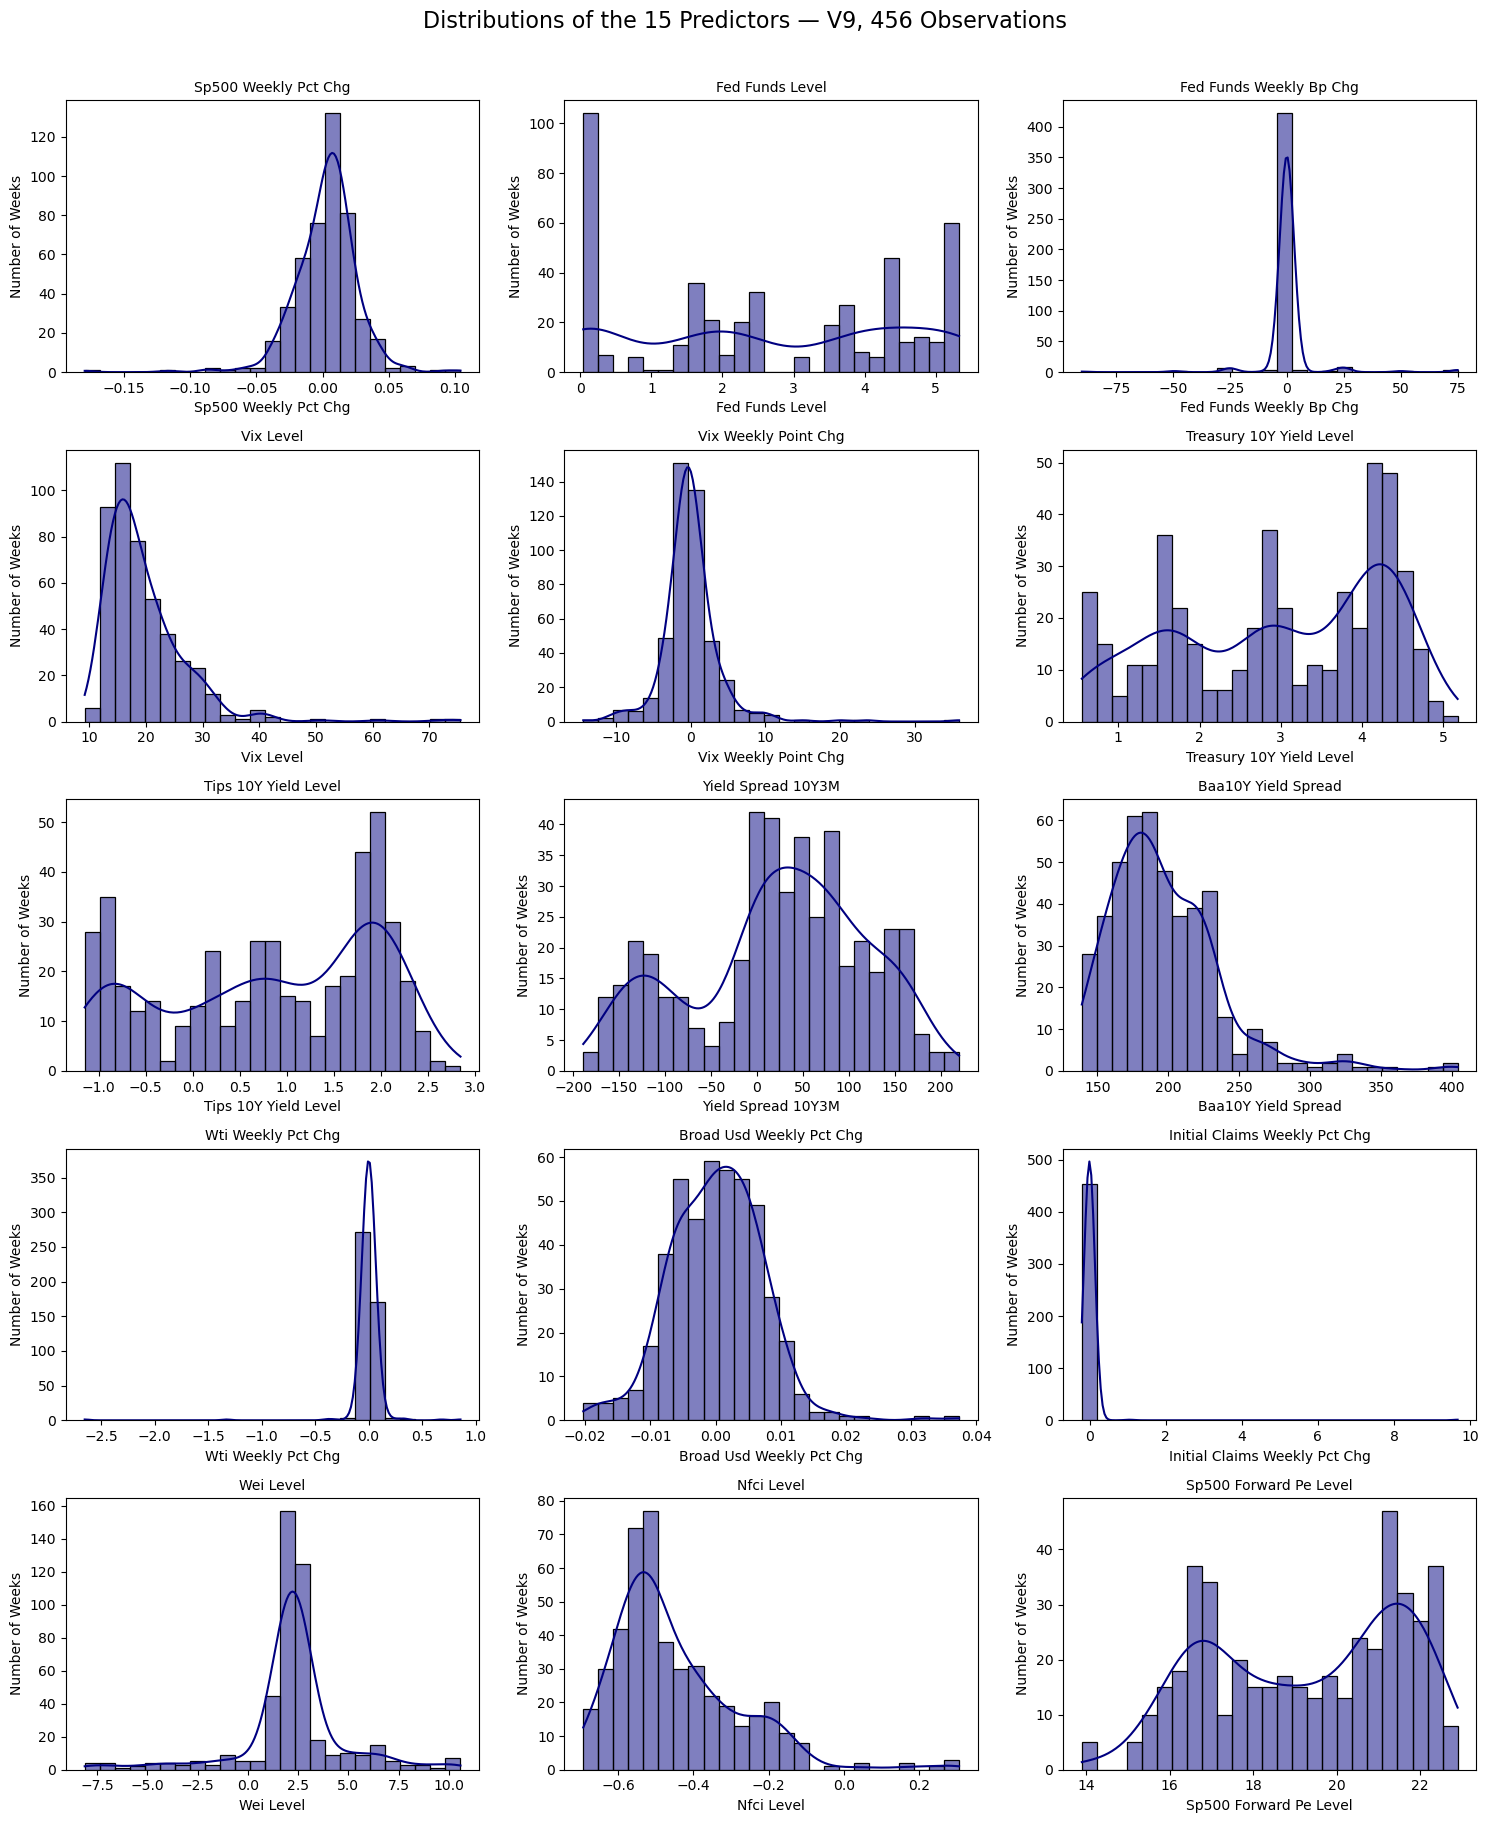

In [6]:
# Several predictors are skewed, non-normal, or concentrated at repeated values.
# Weekly changes cluster near zero, while rate and valuation levels show regime patterns. 

predictor_cols = eda.columns.drop([
    "model_week_end",
    "target_return_next_w"
])

fig, axes = plt.subplots(
    5,
    3,
    figsize=(15, 18)
)

for column, ax in zip(predictor_cols, axes.flat):
    sns.histplot(
        eda[column],
        bins=25,
        kde=True,
        color="navy",
        ax=ax
    )

    ax.set_title(
        column.replace("_", " ").title(),
        fontsize=10
    )

    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Weeks")

fig.suptitle(
    "Distributions of the 15 Predictors — V9, 456 Observations",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

# 6 Pearson and Spearman Correlation Heatmaps

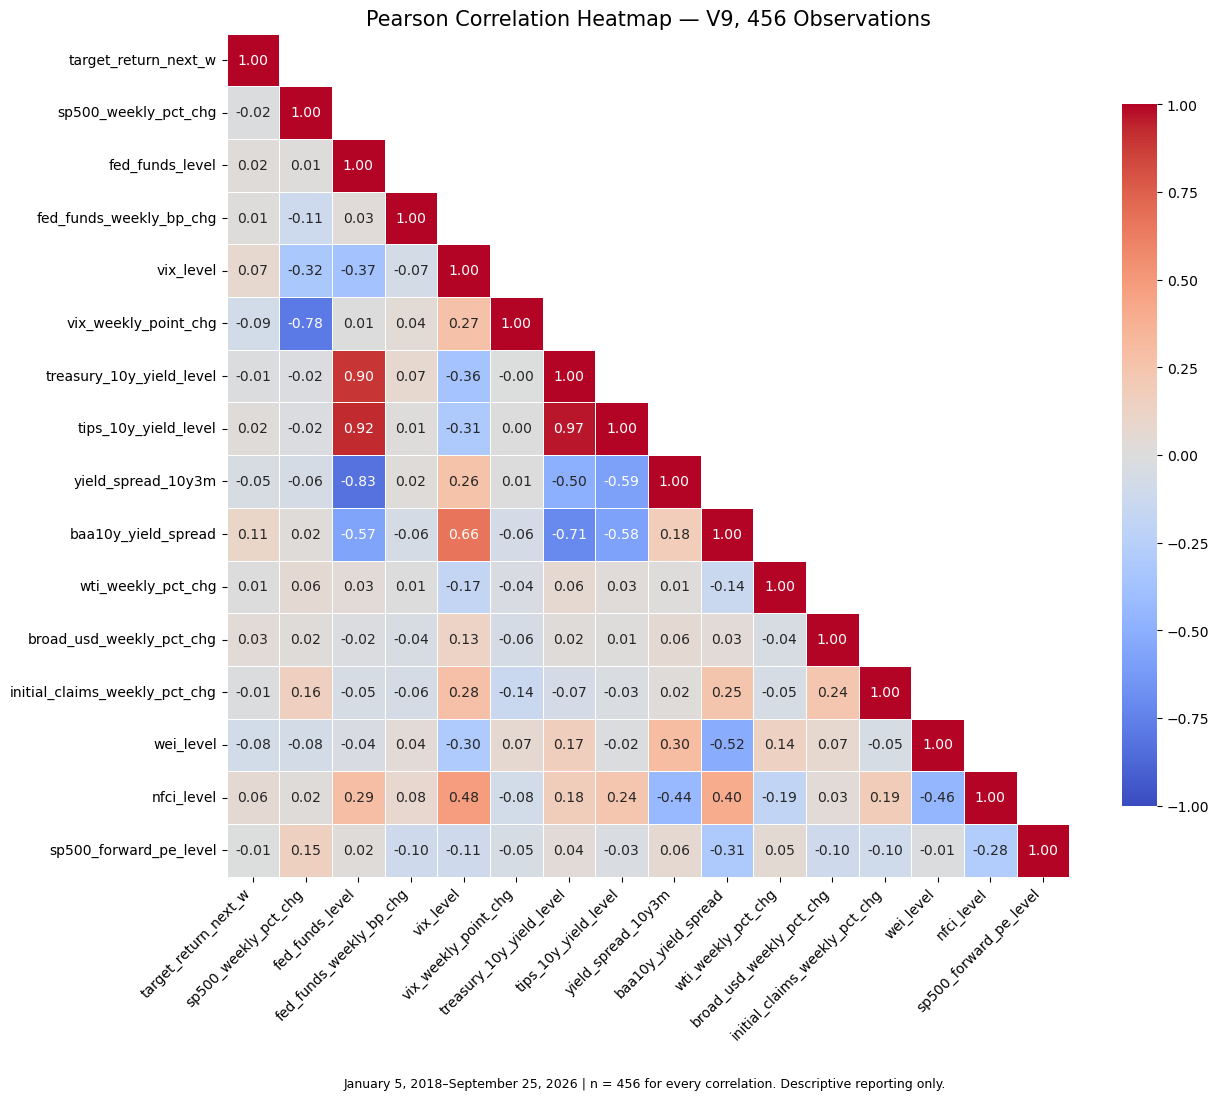

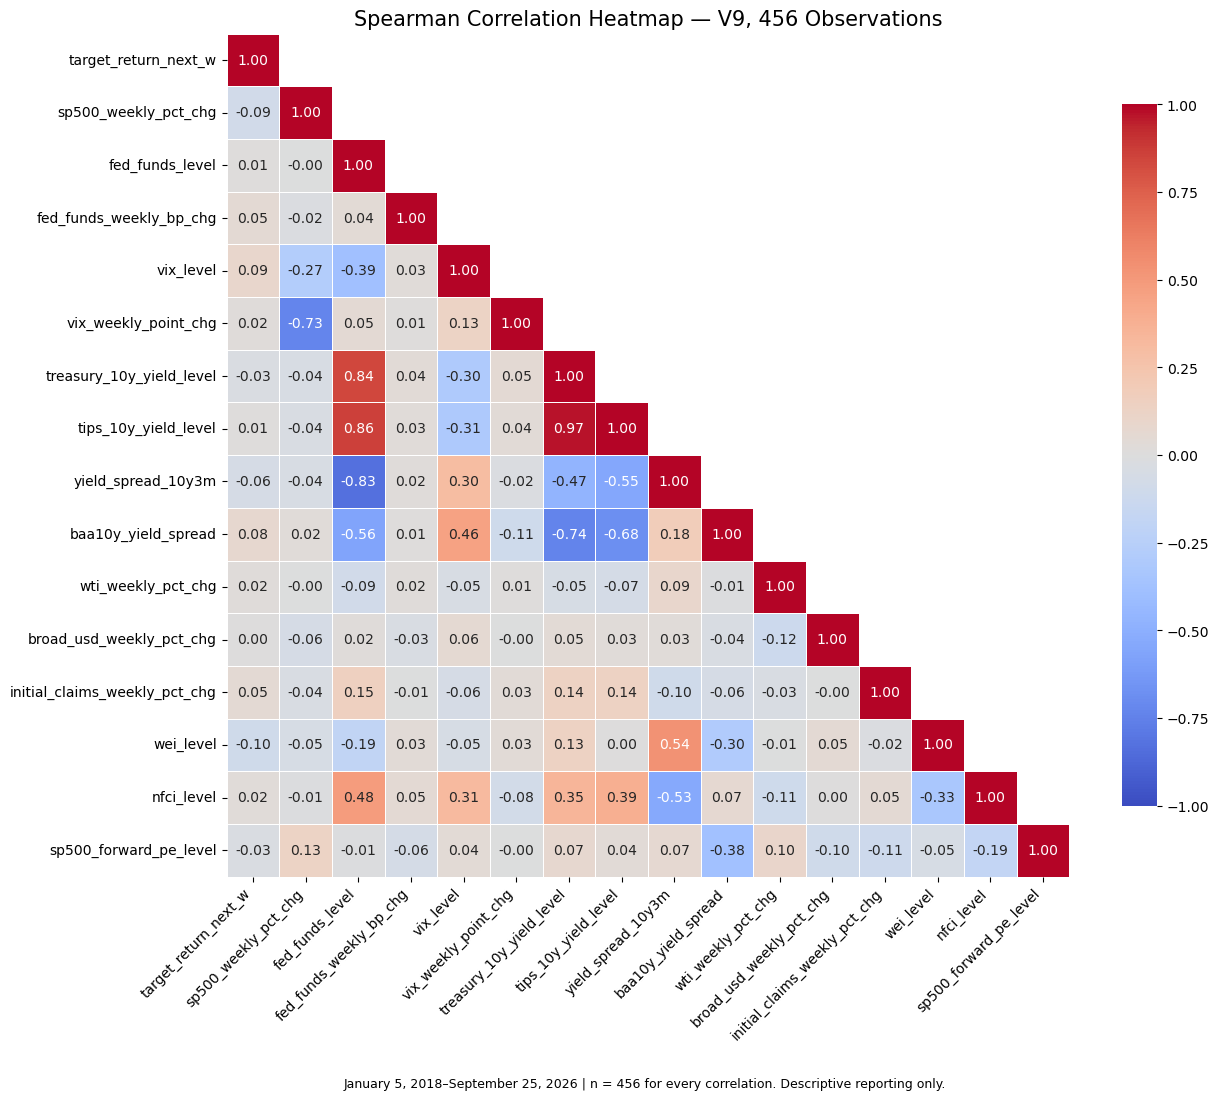

In [7]:

correlation_data = eda.drop(
    columns="model_week_end"
)

for method, title in [
    ("pearson", "Pearson Correlation Heatmap"),
    ("spearman", "Spearman Correlation Heatmap")
]:
    correlation_matrix = correlation_data.corr(
        method=method
    )

    upper_triangle = np.triu(
        np.ones_like(
            correlation_matrix,
            dtype=bool
        ),
        k=1
    )

    plt.figure(figsize=(13, 11))

    sns.heatmap(
        correlation_matrix,
        mask=upper_triangle,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    plt.title(title + ' — V9, 456 Observations', fontsize=15)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.figtext(.5,.01,'January 5, 2018–September 25, 2026 | n = 456 for every correlation. Descriptive reporting only.',ha='center',fontsize=9)
    plt.tight_layout(rect=(0,.04,1,1))
    plt.show()

# 7 Individual Predictor-To-Target Visualizations

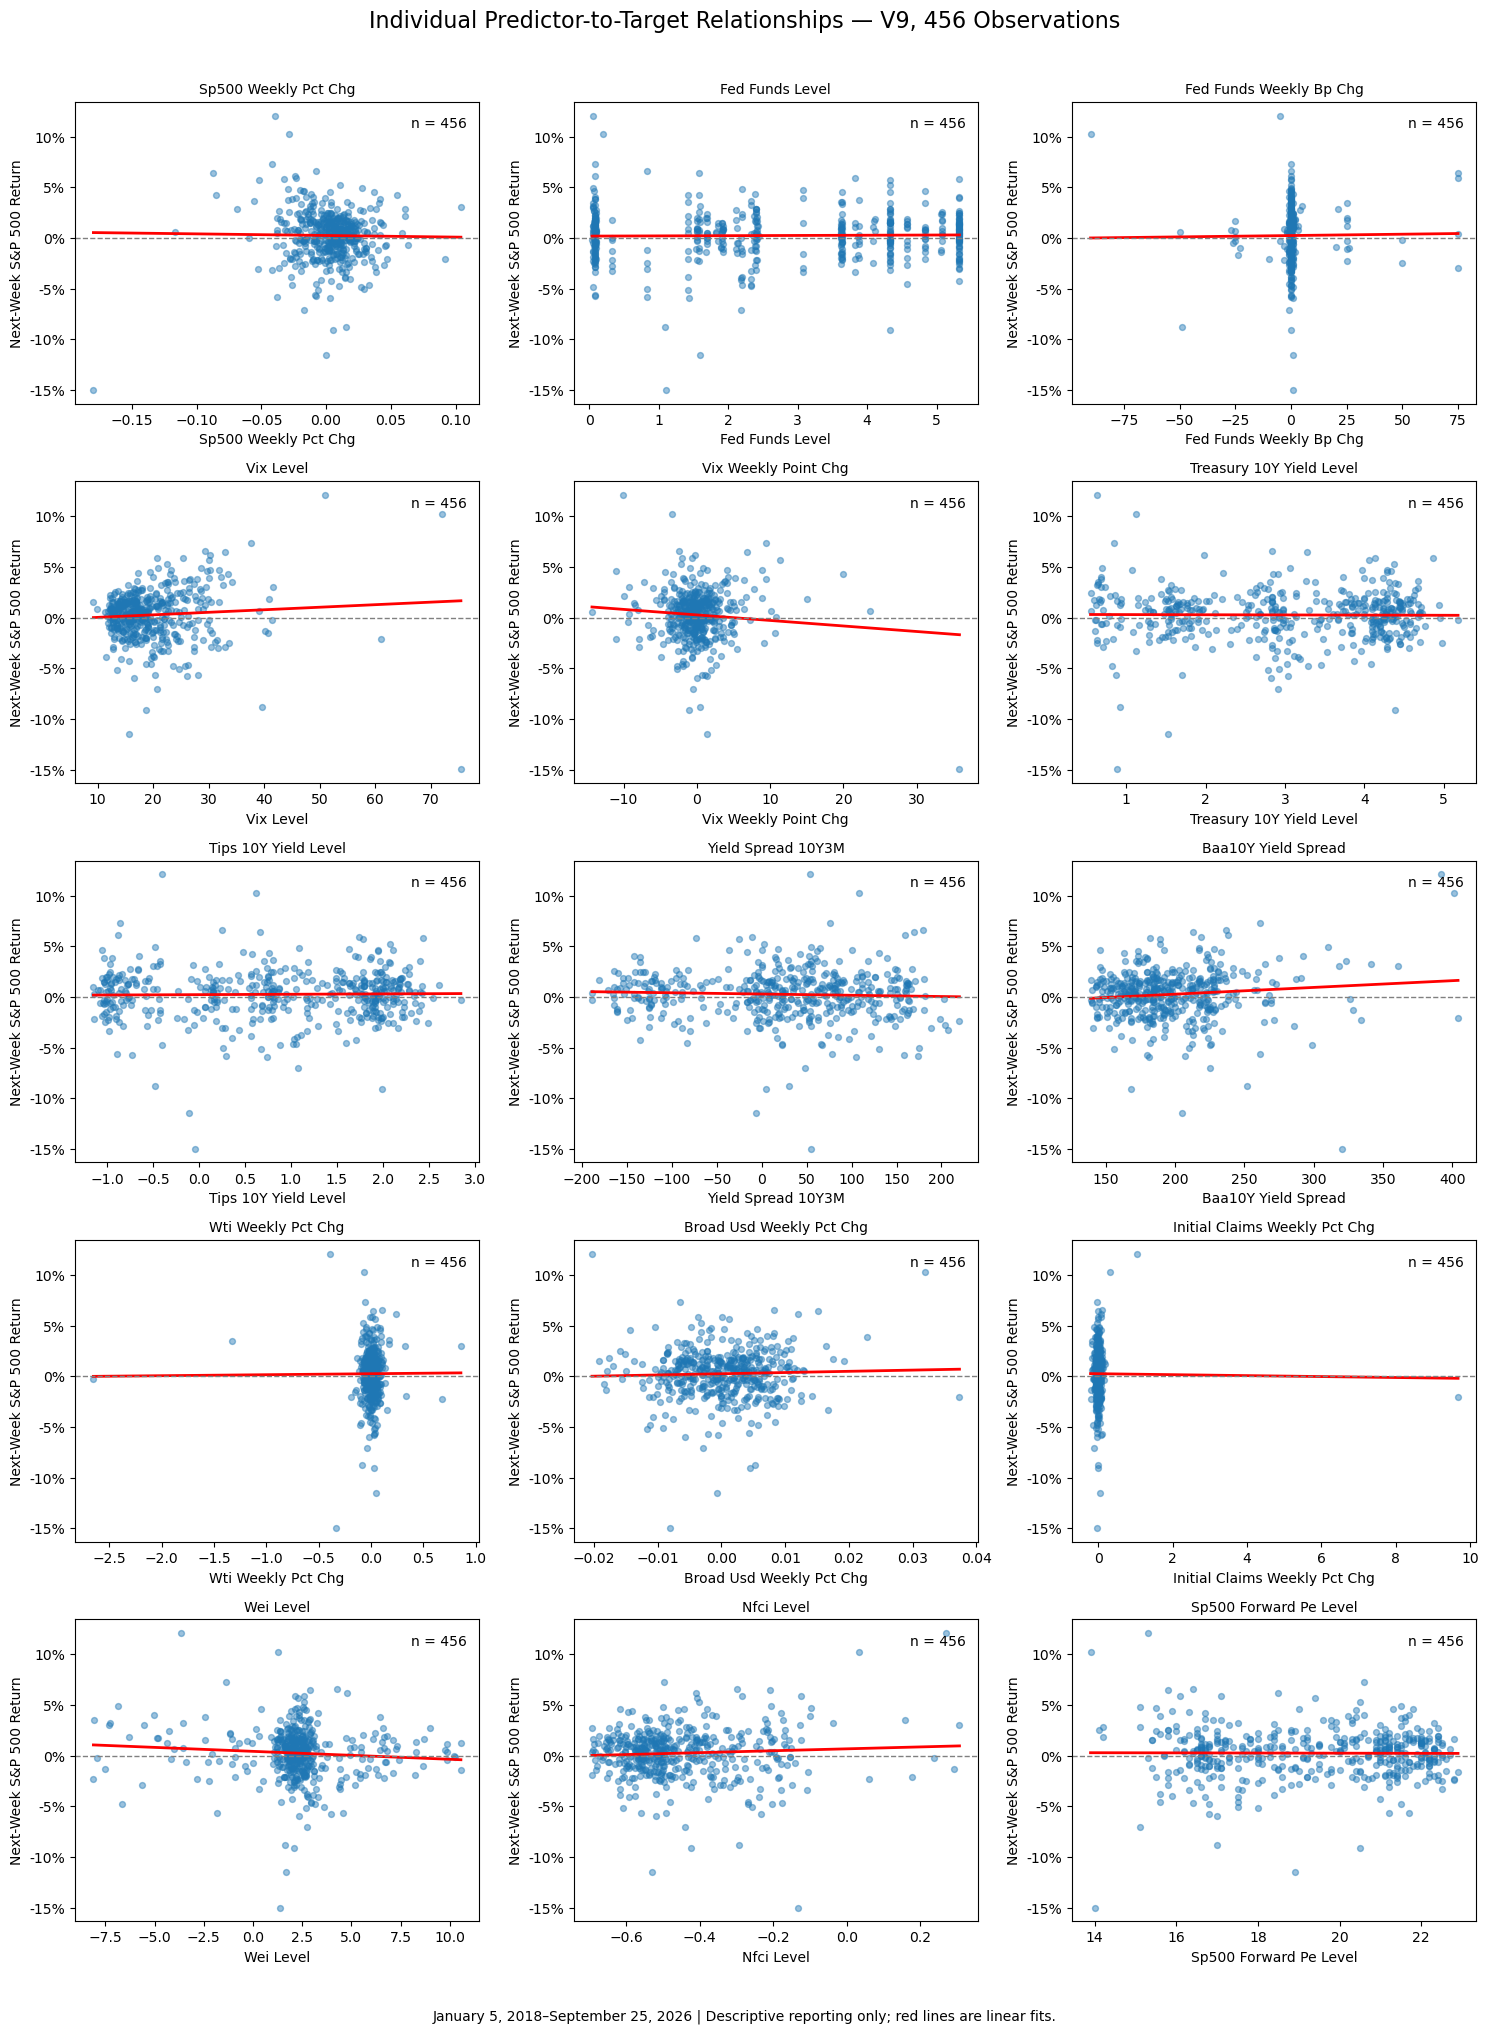

In [8]:
# Plots every predictor against next week's return, with one point per week and a fitted line.
# Most fitted lines are nearly flat and the observations form broad clouds.
# No predictor shows a strong standalone linear relationship with next week's return.

target_col = "target_return_next_w"

fig, axes = plt.subplots(5, 3, figsize=(15, 20))

for column, ax in zip(predictor_cols, axes.flat):
    sns.regplot(
        data=eda,
        x=column,
        y=target_col,
        ci=None,
        scatter_kws={"alpha": 0.45, "s": 18},
        line_kws={"color": "red", "linewidth": 2},
        ax=ax
    )

    ax.text(.97,.95,'n = 456',transform=ax.transAxes,ha='right',va='top')
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(column.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Next-Week S&P 500 Return")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda value, position: f"{value:.0%}")
    )

fig.suptitle(
    "Individual Predictor-to-Target Relationships — V9, 456 Observations",
    fontsize=16,
    y=1.01
)

plt.figtext(.5,.005,'January 5, 2018–September 25, 2026 | Descriptive reporting only; red lines are linear fits.',ha='center')
plt.tight_layout(rect=(0,.025,1,1))
plt.show()

# 8 Correlation P-Values and False-Discovery-Rate Adjustment

P-values are exploratory and use all 456 observations. Weekly observations may be serially dependent, and FDR adjustment does not correct that dependence or establish causation. These results do not guide the frozen model.

In [9]:
# Tests whether each correlation could reasonably occur by chance, then adjusts for testing 15 predictors.

p_values = pd.DataFrame(index=predictor_cols)

p_values["Pearson p"] = [
    stats.pearsonr(eda[column], eda["target_return_next_w"]).pvalue
    for column in predictor_cols
]

p_values["Spearman p"] = [
    stats.spearmanr(eda[column], eda["target_return_next_w"]).pvalue
    for column in predictor_cols
]

p_values["Pearson FDR p"] = multipletests(
    p_values["Pearson p"], method="fdr_bh"
)[1]

p_values["Spearman FDR p"] = multipletests(
    p_values["Spearman p"], method="fdr_bh"
)[1]

display(p_values.sort_values("Pearson FDR p").round(4))

,Pearson p,Spearman p,Pearson FDR p,Spearman FDR p
baa10y_yield_spread,0.0227,0.0958,0.3410,0.3591
vix_weekly_point_chg,0.0679,0.7071,0.3940,0.9176
wei_level,0.0788,0.0334,0.3940,0.2884
vix_level,0.1192,0.0522,0.4471,0.2884
nfci_level,0.1832,0.6137,0.5496,0.9176
yield_spread_10y3m,0.3225,0.2281,0.8063,0.6679
fed_funds_weekly_bp_chg,0.8102,0.2755,0.8944,0.6679
sp500_weekly_pct_chg,0.7455,0.0577,0.8944,0.2884
tips_10y_yield_level,0.7217,0.8565,0.8944,0.9176
treasury_10y_yield_level,0.8517,0.5638,0.8944,0.9176


# 9 Rolling Correlations and Relationship Stability

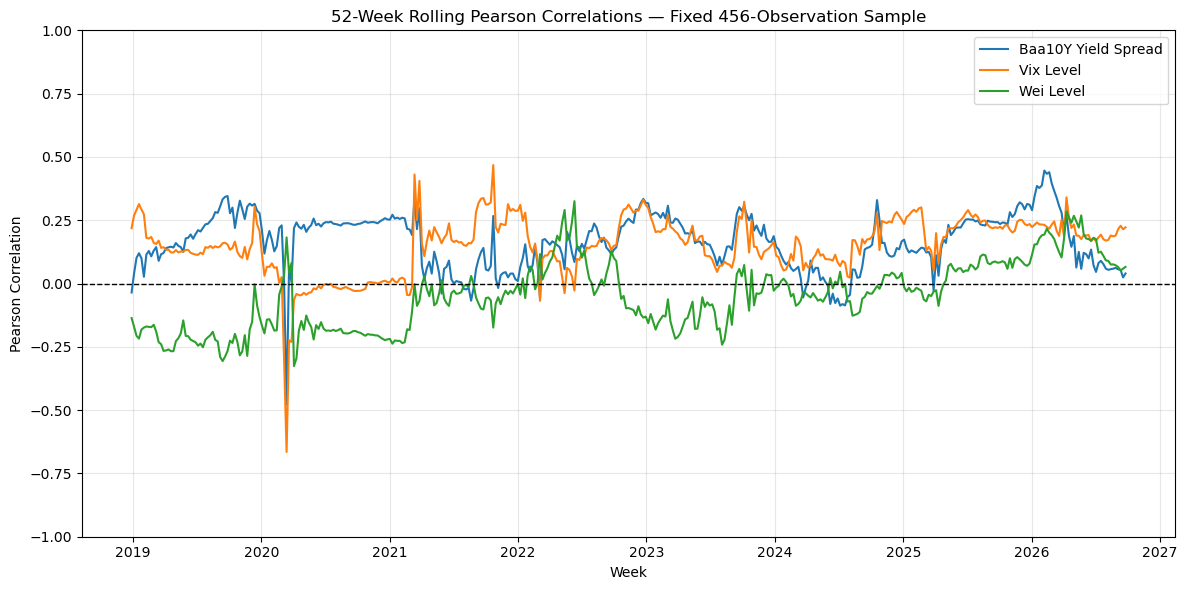

In [10]:

rolling_predictors = [
    "baa10y_yield_spread",
    "vix_level",
    "wei_level"
]

rolling_corr = pd.DataFrame({
    "model_week_end": eda["model_week_end"]
})

for column in rolling_predictors:
    rolling_corr[column] = (
        eda[column]
        .rolling(window=52)
        .corr(eda["target_return_next_w"])
    )

plt.figure(figsize=(12, 6))

for column in rolling_predictors:
    plt.plot(
        rolling_corr["model_week_end"],
        rolling_corr[column],
        label=column.replace("_", " ").title()
    )

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.ylim(-1, 1)
plt.title("52-Week Rolling Pearson Correlations — Fixed 456-Observation Sample")
plt.xlabel("Week")
plt.ylabel("Pearson Correlation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 10 VIF and Multicollinearity Analysis

In [11]:

X = eda[predictor_cols].astype(float)
X = sm.add_constant(X)

vif_results = pd.DataFrame({
    "Predictor": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif_results = (
    vif_results[vif_results["Predictor"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif_results.round(2))

,Predictor,VIF
0,fed_funds_level,231.20
1,treasury_10y_yield_level,108.42
2,tips_10y_yield_level,68.76
3,yield_spread_10y3m,66.20
4,baa10y_yield_spread,10.07
5,nfci_level,5.91
6,vix_level,5.32
7,wei_level,3.72
8,sp500_weekly_pct_chg,3.07
9,vix_weekly_point_chg,2.92


# 11 EDA-Supported Hypotheses

In [12]:
# Descriptive hypotheses only: do not use combined training/test EDA to tune the model.
pearson_to_target=eda[PREDICTOR_NAMES].corrwith(eda[TARGET_COL])
display(pearson_to_target.rename('Pearson correlation with next-week return').to_frame())
print('Correlation is descriptive association, not evidence of economic causation. Nonlinear and lagged effects require separate training-only evaluation.')


,Pearson correlation with next-week return
sp500_weekly_pct_chg,-0.015241
fed_funds_level,0.016246
fed_funds_weekly_bp_chg,0.011276
vix_level,0.073062
vix_weekly_point_chg,-0.085569
treasury_10y_yield_level,-0.008778
tips_10y_yield_level,0.016724
yield_spread_10y3m,-0.046432
baa10y_yield_spread,0.106659
wti_weekly_pct_chg,0.006236


Correlation is descriptive association, not evidence of economic causation. Nonlinear and lagged effects require separate training-only evaluation.


# 12 Recommended Candidate Features And Competing Feature Groups

In [13]:
print('Economic-role groups organized the feature investigation. Timing-by-regime interactions were tested during modeling but were not retained in the final 63-feature model. No group weights were assigned.')
print('The frozen model uses 15 original predictors, 16 two-week lagged predictors, and 32 threshold features. All model selection remains training-only.')


Economic-role groups organized the feature investigation. Timing-by-regime interactions were tested during modeling but were not retained in the final 63-feature model. No group weights were assigned.
The frozen model uses 15 original predictors, 16 two-week lagged predictors, and 32 threshold features. All model selection remains training-only.


# 13 EDA Conclusions, Limitations, and Modeling Handoff

In [14]:
assert len(eda)==456 and len(training_eda)==272 and len(testing_eda)==184
assert len(predictor_cols)==15 and eda.notna().all().all()
assert eda[DATE_COL].iloc[0]==pd.Timestamp('2018-01-05') and eda[DATE_COL].iloc[-1]==pd.Timestamp('2026-09-25')
assert eda[DATE_COL].equals(pd.Series(pd.date_range('2018-01-05','2026-09-25',freq='W-FRI'),name=DATE_COL))
print('EDA FINAL STATUS: PASS — 272 training + 184 testing = 456 observations; V9 approved additions included.')
print('All plots and tables use the same fixed sample. No forecasting model is fitted or modified in this EDA notebook.')


EDA FINAL STATUS: PASS — 272 training + 184 testing = 456 observations; V9 approved additions included.
All plots and tables use the same fixed sample. No forecasting model is fitted or modified in this EDA notebook.
